# Analisis Big Data - Soal 1: Distribusi Jumlah Trip
Data: `trip.csv` (Seattle Cycle Share), letakkan satu folder dengan notebook ini.

| No | Pertanyaan | Bagian |
|----|-----------|--------|
| 1a | Distribusi jumlah trip per tahun | A |
| 1b | Distribusi jumlah trip per bulan | B |
| 1c | Distribusi jumlah trip per hari | C |
| 1d | Plot distribusi frekuensi trip harian | D |
| - | Analisis multivariat | E |

Catatan cakupan data: 13 Okt 2014 s.d. 31 Agu 2016, sehingga 2014 dan 2016 adalah tahun parsial.

## 0. Persiapan data

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA_PATH = 'trip.csv'
TIME_FORMAT = '%m/%d/%Y %H:%M'
WEEKDAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

In [2]:
data = pd.read_csv(DATA_PATH)

start = pd.to_datetime(data['starttime'], format=TIME_FORMAT)
data['year'] = start.dt.year
data['month'] = start.dt.month
data['year_month'] = start.dt.to_period('M')
data['day'] = start.dt.day
data['weekday'] = pd.Categorical(start.dt.day_name(), categories=WEEKDAYS, ordered=True)
data['hour'] = start.dt.hour
data['date'] = start.dt.normalize()

print(f'Rows: {len(data):,} | Missing starttime: {data["starttime"].isnull().sum()}')
print(f'Period: {start.min():%d %b %Y} - {start.max():%d %b %Y}')

Rows: 236,065 | Missing starttime: 0
Period: 13 Oct 2014 - 31 Aug 2016


## A. (1a) Distribusi jumlah trip per tahun

In [3]:
trips_by_year = data.groupby('year').size().rename('trips').to_frame()
trips_by_year['percent'] = (100 * trips_by_year['trips'] / trips_by_year['trips'].sum()).round(2)
trips_by_year

,trips,percent
year,,
2014,20239,8.57
2015,140306,59.44
2016,75520,31.99


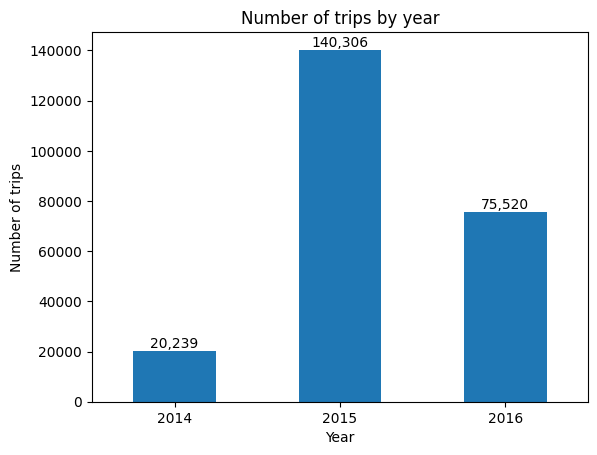

In [4]:
ax = trips_by_year['trips'].plot.bar(title='Number of trips by year', rot=0,
                                      xlabel='Year', ylabel='Number of trips')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
plt.show()

## B. (1b) Distribusi jumlah trip per bulan
Dua sudut pandang: (1) bulan kalender 1-12 untuk melihat pola musiman, dan (2) tahun-bulan untuk melihat tren sepanjang periode.

In [5]:
trips_by_month = data.groupby('month').size().reindex(range(1, 13), fill_value=0)
trips_by_month.index = MONTHS
trips_by_month.to_frame('trips').T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
trips,12530,13116,16953,21927,26035,27547,32150,30239,13134,17190,14364,10880


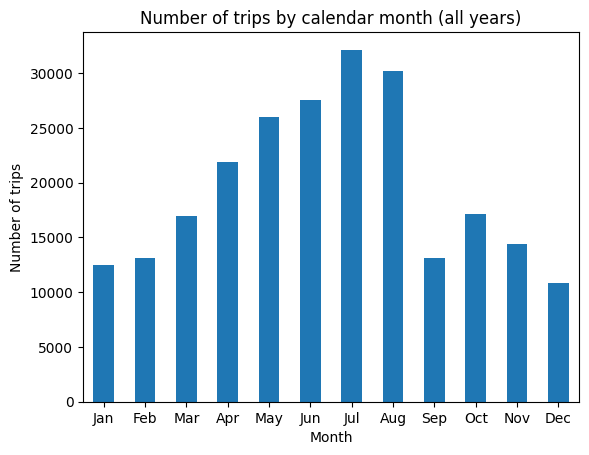

In [6]:
ax = trips_by_month.plot.bar(title='Number of trips by calendar month (all years)', rot=0,
                             xlabel='Month', ylabel='Number of trips')
plt.show()

In [7]:
trips_by_year_month = data.groupby('year_month').size()
trips_by_year_month.to_frame('trips').T

year_month,2014-10,2014-11,2014-12,2015-01,2015-02,2015-03,2015-04,2015-05,2015-06,2015-07,2015-08,2015-09,2015-10,2015-11,2015-12,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06,2016-07,2016-08
trips,6585,7823,5831,7368,7330,9980,12898,15548,15999,18808,17046,13134,10605,6541,5049,5162,5786,6973,9029,10487,11548,13342,13193


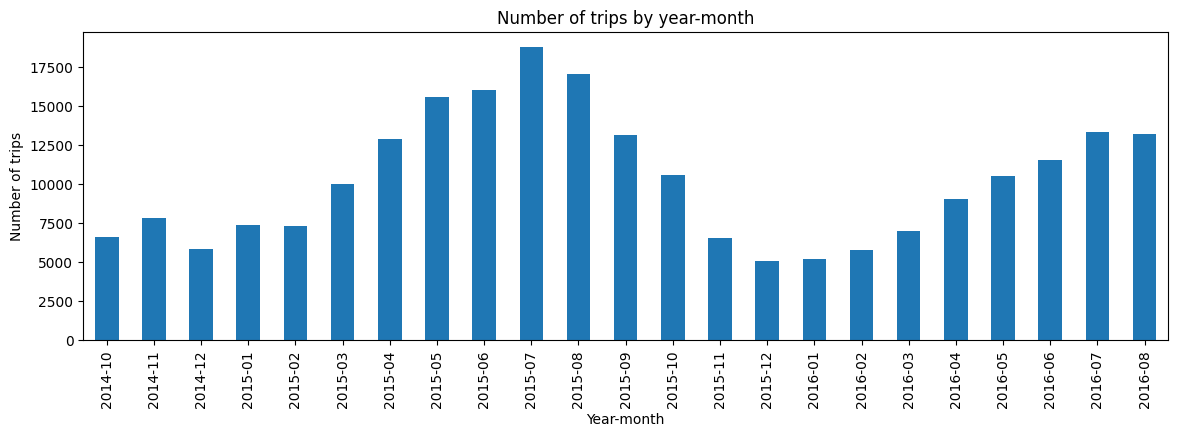

In [8]:
ax = trips_by_year_month.plot.bar(title='Number of trips by year-month', figsize=(14, 4),
                                  xlabel='Year-month', ylabel='Number of trips')
plt.show()

## C. (1c) Distribusi jumlah trip per hari
Dua tafsir "hari": (1) tanggal dalam bulan (1-31) dan (2) hari dalam minggu (Senin-Minggu).

In [9]:
trips_by_day_of_month = data.groupby('day').size()
trips_by_day_of_month.to_frame('trips').T

day,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
trips,7359,7819,7690,7998,7372,7282,7421,8287,8381,7520,7590,7533,7867,7580,7529,8293,7934,8472,8797,8506,7618,7718,7186,7552,7441,7683,7323,7386,7356,7333,4239


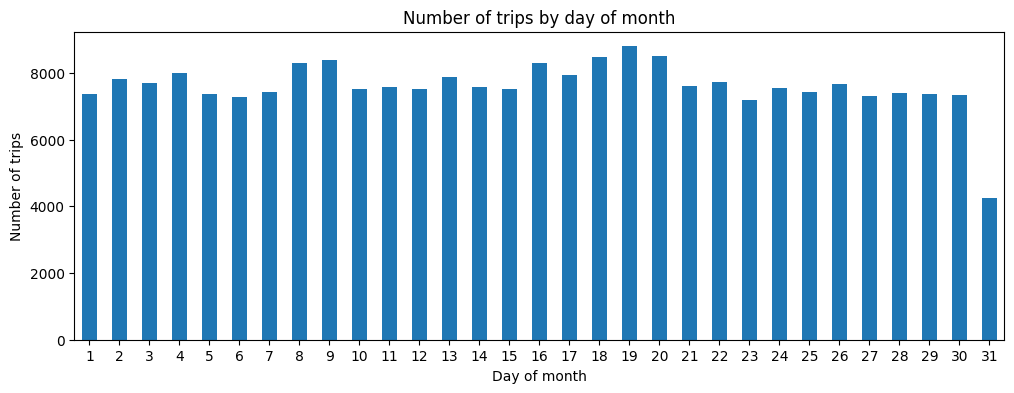

In [10]:
ax = trips_by_day_of_month.plot.bar(title='Number of trips by day of month', figsize=(12, 4),
                                    rot=0, xlabel='Day of month', ylabel='Number of trips')
plt.show()

In [11]:
trips_by_weekday = data.groupby('weekday', observed=False).size().rename('trips').to_frame()
trips_by_weekday['percent'] = (100 * trips_by_weekday['trips'] / trips_by_weekday['trips'].sum()).round(2)
trips_by_weekday

,trips,percent
weekday,,
Monday,34704,14.70
Tuesday,35023,14.84
Wednesday,35263,14.94
Thursday,36122,15.30
Friday,35828,15.18
Saturday,31724,13.44
Sunday,27401,11.61


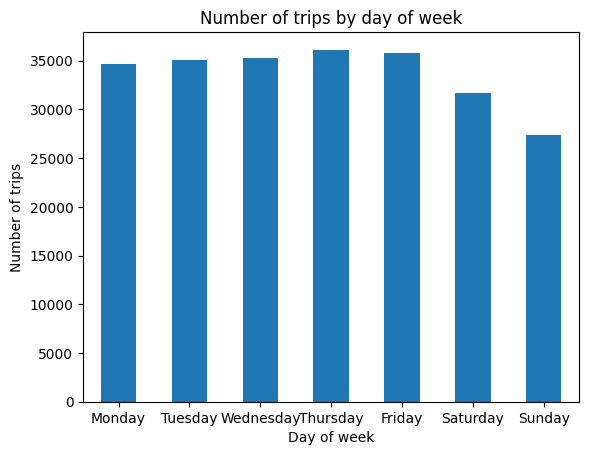

In [12]:
ax = trips_by_weekday['trips'].plot.bar(title='Number of trips by day of week', rot=0,
                                        xlabel='Day of week', ylabel='Number of trips')
plt.show()

## D. (1d) Plot distribusi frekuensi trip pada basis harian

In [13]:
daily_trips = data.groupby('date').size().rename('trips')
daily_trips.describe().round(2).to_frame().T

,count,mean,std,min,25%,50%,75%,max
trips,689.0,342.62,154.86,30.0,230.0,325.0,440.0,941.0


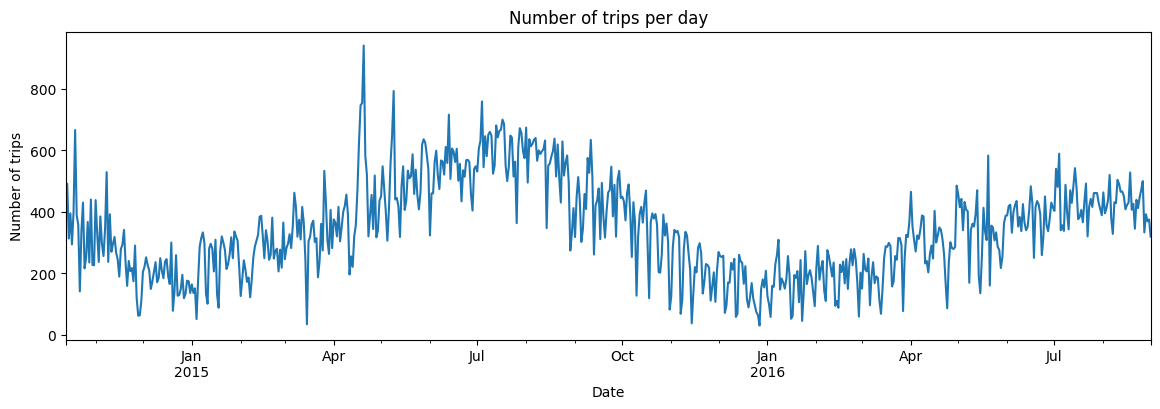

In [14]:
ax = daily_trips.plot(title='Number of trips per day', figsize=(14, 4),
                      xlabel='Date', ylabel='Number of trips')
plt.show()

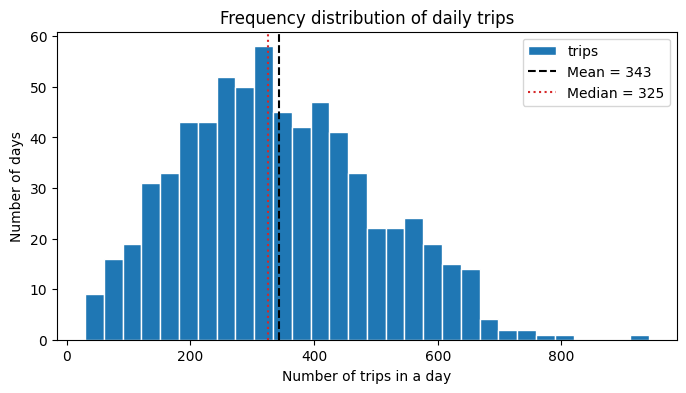

In [15]:
ax = daily_trips.plot.hist(bins=30, edgecolor='white', figsize=(8, 4),
                           title='Frequency distribution of daily trips')
ax.set_xlabel('Number of trips in a day')
ax.set_ylabel('Number of days')
ax.axvline(daily_trips.mean(), color='black', linestyle='--', label=f'Mean = {daily_trips.mean():.0f}')
ax.axvline(daily_trips.median(), color='tab:red', linestyle=':', label=f'Median = {daily_trips.median():.0f}')
ax.legend()
plt.show()

## E. Analisis multivariat
Hubungan jumlah trip dengan lebih dari satu variabel: tipe pengguna, hari, jam, dan durasi.

### E1. Bulan x tipe pengguna

In [16]:
month_user = (data.groupby(['month', 'usertype']).size()
              .unstack('usertype', fill_value=0)
              .reindex(range(1, 13), fill_value=0))
month_user.index = MONTHS
month_user

usertype,Member,Short-Term Pass Holder
Jan,9902,2628
Feb,9623,3493
Mar,11462,5491
Apr,12856,9071
May,14943,11092
Jun,15425,12122
Jul,16057,16093
Aug,15937,14302
Sep,8194,4940
Oct,12287,4903


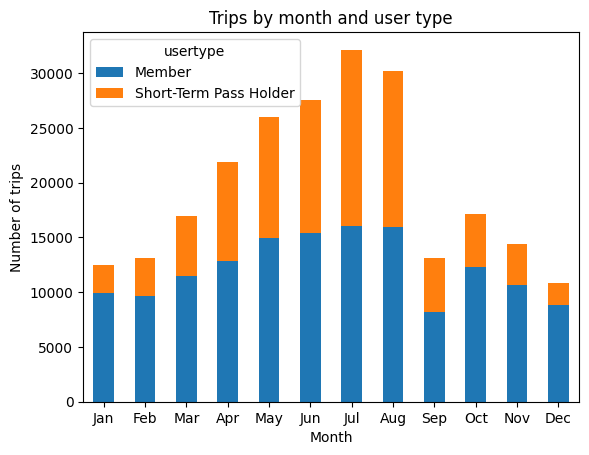

In [17]:
ax = month_user.plot.bar(stacked=True, rot=0, title='Trips by month and user type',
                         xlabel='Month', ylabel='Number of trips')
plt.show()

### E2. Hari dalam minggu x tipe pengguna (persentase per tipe)

In [18]:
weekday_user = (data.groupby(['weekday', 'usertype'], observed=False).size()
                .unstack('usertype'))
weekday_user_pct = (100 * weekday_user / weekday_user.sum()).round(1)
weekday_user_pct

usertype,Member,Short-Term Pass Holder
weekday,,
Monday,16.1,12.5
Tuesday,18.0,9.7
Wednesday,18.1,9.8
Thursday,17.6,11.5
Friday,16.3,13.4
Saturday,7.4,23.2
Sunday,6.6,19.8


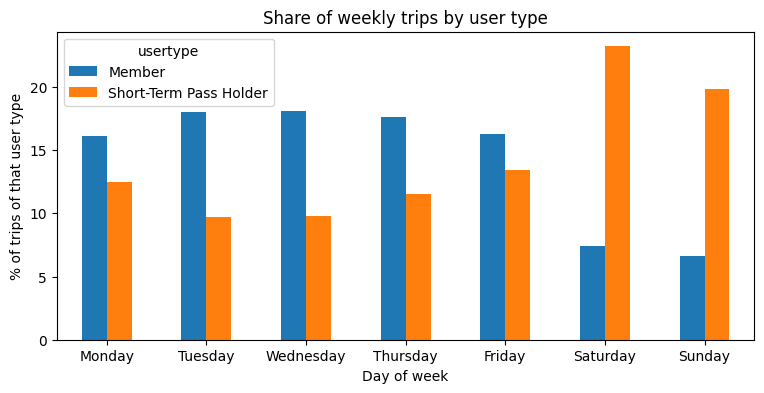

In [19]:
ax = weekday_user_pct.plot.bar(rot=0, figsize=(9, 4), title='Share of weekly trips by user type',
                               xlabel='Day of week', ylabel='% of trips of that user type')
plt.show()

### E3. Hari x jam (heatmap)

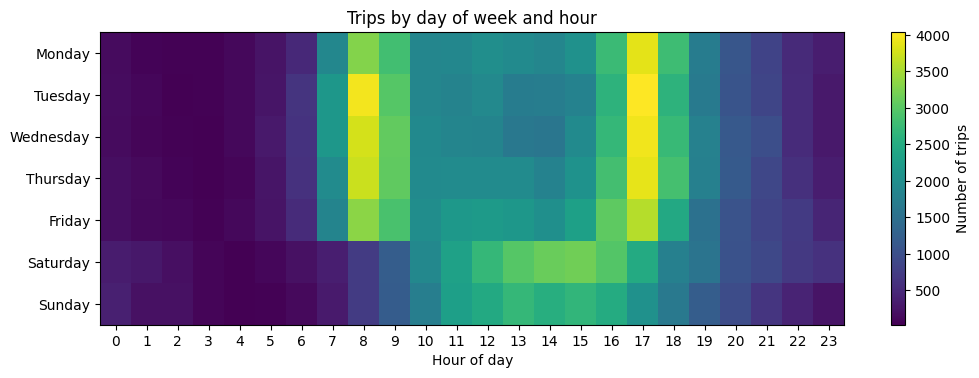

In [20]:
weekday_hour = (data.groupby(['weekday', 'hour'], observed=False).size()
                .unstack('hour', fill_value=0))
fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(weekday_hour.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(WEEKDAYS)
ax.set_xlabel('Hour of day')
ax.set_title('Trips by day of week and hour')
fig.colorbar(image, ax=ax, label='Number of trips')
plt.show()

### E4. Jumlah trip harian vs rata-rata durasi harian

In [21]:
daily = data.groupby('date').agg(trips=('trip_id', 'size'),
                                  mean_duration=('tripduration', 'mean'))
print(f'Pearson correlation (trips vs mean duration): '
      f'{daily["trips"].corr(daily["mean_duration"]):.3f}')
print(f'Spearman correlation: '
      f'{daily["trips"].rank().corr(daily["mean_duration"].rank()):.3f}')

Pearson correlation (trips vs mean duration): 0.284
Spearman correlation: 0.374


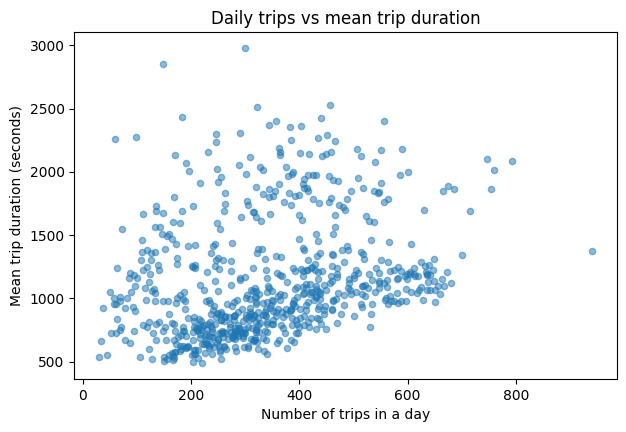

In [22]:
ax = daily.plot.scatter(x='trips', y='mean_duration', alpha=0.5, figsize=(7, 4.5),
                        title='Daily trips vs mean trip duration')
ax.set_xlabel('Number of trips in a day')
ax.set_ylabel('Mean trip duration (seconds)')
plt.show()

### E5. Tipe pengguna x tahun

In [23]:
year_user = data.groupby(['year', 'usertype']).size().unstack('usertype')
year_user['member_share_%'] = (100 * year_user['Member'] / year_user.sum(axis=1)).round(1)
year_user

usertype,Member,Short-Term Pass Holder,member_share_%
year,,,
2014,13879,6360,68.6
2015,88262,52044,62.9
2016,44030,31490,58.3
